In [1]:
%pip install pandas matplotlib statsmodels

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: C:\Users\HoangHoanh\AppData\Local\Python\pythoncore-3.14-64\python.exe -m pip install --upgrade pip


----- THONG TIN DU LIEU -----
So luong quan sat: 144
Thoi gian bat dau: 1949-01-01 00:00:00
Thoi gian ket thuc: 1960-12-01 00:00:00


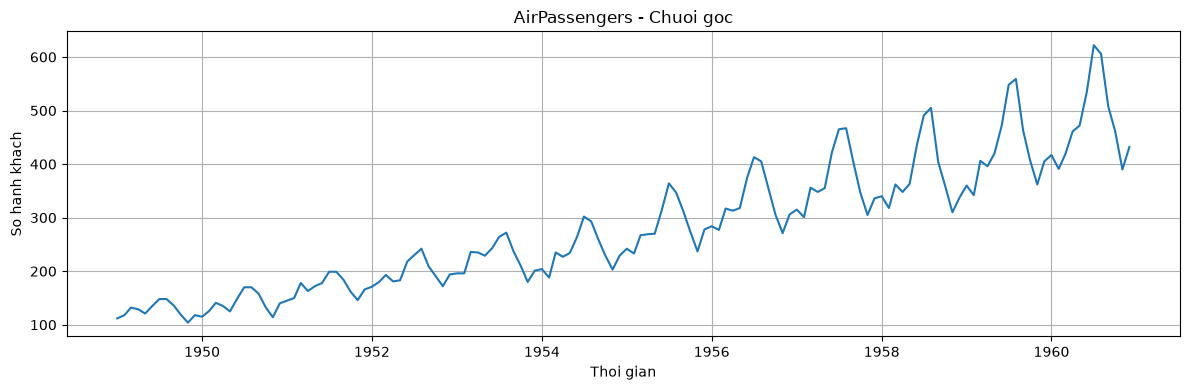

C:\Users\HoangHoanh\AppData\Local\Temp\ipykernel_21480\843982237.py:32: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_goc = adfuller(air_passengers)



----- ADF LAN 1: CHUOI GOC -----
ADF Statistic: 0.815369
p-value: 0.99188
Ket luan: Chua du bang chung de ket luan chuoi goc dung.

----- SAI PHAN BAC 1 -----
So quan sat truoc sai phan: 144
So quan sat sau sai phan: 143


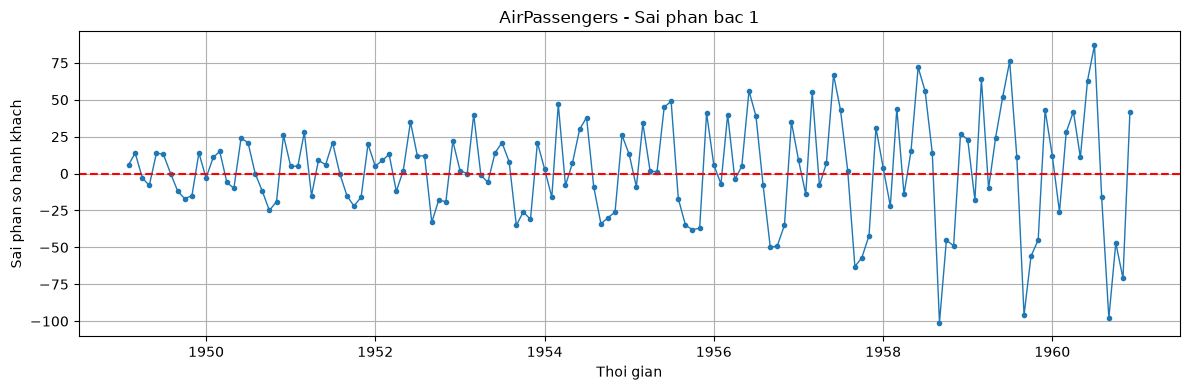


----- ADF LAN 2: SAU SAI PHAN BAC 1 -----
ADF Statistic: -2.829267
p-value: 0.054213
Gia tri toi han:
1%: -3.481682
5%: -2.884042
10%: -2.578770

----- KET LUAN BAI 3 -----
Sau phan sai chuoi chua du bang chung de ket luan da dung
sau sai phan bac 1 o muc y nghia 5%.
Can xem xet them tinh mua vu va cac phep bien doi.
Chua the xac nhan d = 1 chi dua vao ket qua nay.

Chu ky mua vu cua du lieu: s = 12 thang.


C:\Users\HoangHoanh\AppData\Local\Temp\ipykernel_21480\843982237.py:68: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_diff1 = adfuller(air_diff1)


In [9]:
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import adfuller

# 1. DOC DU LIEU
url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/airline-passengers.csv"

df = pd.read_csv(url, parse_dates=["Month"], index_col="Month")
air_passengers = df["Passengers"]

print("----- THONG TIN DU LIEU -----")
print("So luong quan sat:", len(air_passengers))
print("Thoi gian bat dau:", air_passengers.index.min())
print("Thoi gian ket thuc:", air_passengers.index.max())

# 2. VE DO THI CHUOI GOC
plt.figure(figsize=(12, 4))
plt.plot(air_passengers.index, air_passengers.values)
plt.title("AirPassengers - Chuoi goc")
plt.xlabel("Thoi gian")
plt.ylabel("So hanh khach")
plt.grid(True)
plt.tight_layout()
plt.show()

# 3. KIEM DINH ADF LAN 1 - CHUOI GOC
adf_goc = adfuller(air_passengers)

print("\n----- ADF LAN 1: CHUOI GOC -----")
print("ADF Statistic:", round(adf_goc[0], 6))
print("p-value:", round(adf_goc[1], 6))

if adf_goc[1] < 0.05:
    print("Ket luan: Chuoi goc co tinh dung theo ADF (muc 5%).")
else:
    print("Ket luan: Chua du bang chung de ket luan chuoi goc dung.")

# 4. SAI PHAN BAC 1
air_diff1 = air_passengers.diff().dropna()

print("\n----- SAI PHAN BAC 1 -----")
print("So quan sat truoc sai phan:", len(air_passengers))
print("So quan sat sau sai phan:", len(air_diff1))

# 5. VE DO THI SAU SAI PHAN BAC 1
plt.figure(figsize=(12, 4))
plt.plot(
    air_diff1.index,
    air_diff1.values,
    marker="o",
    markersize=3,
    linewidth=1
)
plt.axhline(y=0, color="red", linestyle="--")
plt.title("AirPassengers - Sai phan bac 1")
plt.xlabel("Thoi gian")
plt.ylabel("Sai phan so hanh khach")
plt.grid(True)
plt.tight_layout()
plt.show()

# 6. KIEM DINH ADF LAN 2 - SAU SAI PHAN BAC 1
adf_diff1 = adfuller(air_diff1)

print("\n----- ADF LAN 2: SAU SAI PHAN BAC 1 -----")
print("ADF Statistic:", round(adf_diff1[0], 6))
print("p-value:", round(adf_diff1[1], 6))
print("Gia tri toi han:")

for muc, gia_tri in adf_diff1[4].items():
    print(f"{muc}: {gia_tri:.6f}")

# 7. KET LUAN
print("\n----- KET LUAN BAI 3 -----")

if adf_diff1[1] < 0.05:
    print("Chuoi da dung sau sai phan bac 1.")
    print("Gia tri d trong ARIMA: d = 1.")
else:
    print("Sau phan sai chuoi chua du bang chung de ket luan da dung")
    print("sau sai phan bac 1 o muc y nghia 5%.")
    print("Can xem xet them tinh mua vu va cac phep bien doi.")
    print("Chua the xac nhan d = 1 chi dua vao ket qua nay.")

print("\nChu ky mua vu cua du lieu: s = 12 thang.")
